# Qual é o melhor plano?

Você trabalha como analista para a empresa de telecomunicações Megaline. A empresa oferece aos clientes dois planos pré-pagos: Surf e Ultimate. O departamento comercial quer saber qual dos planos gera mais receita para ajustar o orçamento de publicidade.

Você vai realizar uma análise preliminar dos planos com base em uma pequena seleção de clientes. Você terá dados de 500 clientes da Megaline: que clientes são, de onde eles são, qual plano usam e o número de chamadas e mensagens realizadas em 2018. Seu trabalho é analisar o comportamento dos clientes e determinar qual plano pré-pago gera mais receita.

[Fornecemos alguns comentários para guiar sua linha de raciocínio enquanto você trabalha neste projeto. Entretanto, certifique-se de remover todos os comentários entre colchetes antes de enviar o projeto.]

[Antes de começar a análise dos dados, explique com suas próprias palavras o propósito do projeto e as ações que planeja realizar.]

[Tenha em mente que estudar, modificar e analisar dados é um processo iterativo. É normal retornar a etapas anteriores e corrigir/expandir algo para permitir as próximas etapas.]

O objetivo deste projeto é analisar o comportamento dos clientes da Megaline e comparar os planos pré-pagos Surf e Ultimate para identificar qual deles gera mais receita. Para isso, serão analisados dados de uso de chamadas, mensagens e internet de 500 clientes durante o ano de 2018. A análise ajudará a entender qual plano é mais lucrativo para a empresa.

## Inicialização

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # Carregando todas as bibliotecas



## Carregue os dados

In [2]:
users = pd.read_csv('/datasets/megaline_users.csv')

calls = pd.read_csv('/datasets/megaline_calls.csv')

messages = pd.read_csv('/datasets/megaline_messages.csv')

internet = pd.read_csv('/datasets/megaline_internet.csv')

plans = pd.read_csv('/datasets/megaline_plans.csv') # Carregue os arquivos de dados em diferentes DataFrames



## Prepare os dados

[Os dados deste projeto estão divididos em várias tabelas. Explore cada uma para obter uma compreensão inicial dos dados. Faça correções em cada tabela, se necessário.]

## Planos

In [3]:
plans.info() # Imprima informações gerais/resumo sobre o DataFrame dos planos



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes


In [4]:
plans.head() # Imprima uma amostra de dados dos planos



,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]
O DataFrame plans contém informações sobre os dois planos oferecidos pela Megaline. Todas as colunas possuem valores completos, sem dados ausentes. Os tipos de dados também parecem apropriados para análise, portanto não foram identificados problemas que necessitem correção nesta etapa.

## Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [5]:
# Nenhum problema óbvio foi encontrado nos dados do DataFrame plans.

## Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [6]:
#Neste estágio inicial não foi necessário adicionar novos fatores ao conjunto de dados. No entanto, durante as etapas posteriores da análise, poderão ser criadas variáveis adicionais, como uso mensal de minutos, mensagens e dados por cliente.

## Usuários

In [7]:
users.info() # Imprima informações gerais/resumo sobre o DataFrame dos usuários



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


In [8]:
users.head() # Imprima uma amostra de dados dos usuários



,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaN
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaN
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaN
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaN
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaN


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]
O DataFrame users contém informações sobre os clientes, como ID do usuário, cidade, plano utilizado e datas de registro e cancelamento. A estrutura dos dados parece adequada para análise. No entanto, algumas colunas de data, como reg_date e churn_date, podem precisar ser convertidas para o formato datetime para facilitar análises temporais. Além disso, valores ausentes na coluna churn_date são esperados, pois indicam que alguns usuários ainda não cancelaram o serviço. Esses ajustes podem ser feitos utilizando funções de conversão de data do pandas.

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [9]:
calls['call_date'] = pd.to_datetime(calls['call_date'])

### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [10]:
calls['month'] = calls['call_date'].dt.month

## Chamadas

In [11]:
calls.info() # Imprima informações gerais/resumo sobre o DataFrame das chamadas



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  object        
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[ns]
 3   duration   137735 non-null  float64       
 4   month      137735 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(2), object(1)
memory usage: 5.3+ MB


In [12]:
calls.head() # Imprima uma amostra de dados das chamadas



,id,user_id,call_date,duration,month
0,1000_93,1000,2018-12-27,8.52,12
1,1000_145,1000,2018-12-27,13.66,12
2,1000_247,1000,2018-12-27,14.48,12
3,1000_309,1000,2018-12-28,5.76,12
4,1000_380,1000,2018-12-30,4.22,12


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]


O DataFrame calls contém informações sobre as chamadas realizadas pelos usuários, incluindo ID do usuário, duração da chamada e data da chamada. A coluna de data foi convertida para o formato datetime para facilitar análises temporais. Além disso, foi criada uma nova coluna representando o mês da chamada, o que permitirá calcular o uso mensal de minutos por usuário nas próximas etapas da análise.

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [13]:
calls['call_date'] = pd.to_datetime(calls['call_date'])

### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [14]:
calls['month'] = calls['call_date'].dt.month

## Mensagens

In [15]:
messages.info() # Imprima informações gerais/resumo sobre o DataFrame das mensagens



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


In [16]:
messages.head() # Imprima uma amostra dos dados das mensagens



,id,user_id,message_date
0,1000_125,1000,2018-12-27
1,1000_160,1000,2018-12-31
2,1000_223,1000,2018-12-31
3,1000_251,1000,2018-12-27
4,1000_255,1000,2018-12-26


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]
O DataFrame messages contém informações sobre as mensagens enviadas pelos usuários, incluindo o ID do usuário e a data em que cada mensagem foi enviada. A estrutura dos dados parece adequada para análise. No entanto, a coluna message_date deve ser convertida para o formato datetime para facilitar análises temporais. Não foram observados outros problemas evidentes nos tipos de dados ou valores ausentes.

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [17]:
messages['message_date'] = pd.to_datetime(messages['message_date'])

### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [18]:
messages['month'] = messages['message_date'].dt.month

## Internet

In [19]:
internet.info() # Imprima informações gerais/resumo sobre o DataFrame da internet



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


In [20]:
internet.head()#  Imprima uma amostra de dados para o tráfego da internet



,id,user_id,session_date,mb_used
0,1000_13,1000,2018-12-29,89.86
1,1000_204,1000,2018-12-31,0.00
2,1000_379,1000,2018-12-28,660.40
3,1000_413,1000,2018-12-26,270.99
4,1000_442,1000,2018-12-27,880.22


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

O DataFrame internet contém informações sobre o uso de dados pelos usuários, incluindo o ID do usuário, a quantidade de dados utilizados e a data da sessão. A estrutura geral dos dados parece adequada para análise. No entanto, a coluna session_date precisa ser convertida para o formato datetime para facilitar análises temporais.

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [21]:
internet['session_date'] = pd.to_datetime(internet['session_date'])

### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [22]:
internet['month'] = internet['session_date'].dt.month

## Estude as condições dos planos

[É fundamental entender como os planos funcionam, ou seja, como as cobranças dos usuários são feitas com base na assinatura. Sugerimos imprimir as informações sobre os planos para visualizar novamente as condições.]

In [23]:
plans.head()# Imprima as condições dos planos e certifique-se de que elas fazem sentido para você



,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


## Agregue os dados por usuário

[Agora, como os dados estão limpos, os agregue por usuário e por período para ter apenas um registro dessas informações. Isso vai facilitar muito as próximas análises.]

In [24]:
calls_per_user = calls.groupby(['user_id','month'])['id'].count().reset_index()# Calcule o número de chamadas feitas por cada usuário por mês. Salve o resultado.



In [25]:
minutes_per_user = calls.groupby(['user_id','month'])['duration'].sum().reset_index()# Calcule a quantidade de minutos gastos por cada usuário por mês. Salve o resultado.



In [26]:
messages_per_user = messages.groupby(['user_id','month'])['id'].count().reset_index()
messages_per_user.rename(columns={'id': 'messages'}, inplace=True)# Calcule o número de mensagens enviadas por cada usuário por mês. Salve o resultado.



In [27]:
internet_per_user = internet.groupby(['user_id','month'])['mb_used'].sum().reset_index()# Calcule o volume de tráfego de internet usado por cada usuário por mês. Salve o resultado.



[Coloque os dados agregados em um DataFrame para que cada registro nele represente o que cada usuário consumiu em um determinado mês.]

In [28]:

data = calls_per_user.merge(minutes_per_user, on=['user_id','month'], how='outer')

data = data.merge(messages_per_user, on=['user_id','month'], how='outer')

data = data.merge(internet_per_user, on=['user_id','month'], how='outer')
data = data.merge(users[['user_id','city']], on='user_id', how='left')
data[['duration','mb_used','messages']] = data[['duration','mb_used','messages']].fillna(0)
print(data.columns)# Junte os dados de chamadas, minutos, mensagens e internet com base em user_id e month




Index(['user_id', 'month', 'id', 'duration', 'messages', 'mb_used', 'city'], dtype='object')


In [29]:
data.isna().sum()

user_id      0
month        0
id          35
duration     0
messages     0
mb_used      0
city         0
dtype: int64

In [30]:
data = data.merge(users[['user_id','plan']], on='user_id')

data = data.merge(plans, left_on='plan', right_on='plan_name')# Adicione as informações sobre o plano



[Calcule a receita mensal para cada usuário: subtraia o limite gratuito do pacote do número total de chamadas, mensagens de texto e dados; multiplique o resultado pelo valor do plano; adicione o preço mensal dependendo do plano. Importante: isso talvez não seja tão simples e necessite de várias linhas, considerando as condições do plano. Portanto, não se preocupe se você passar algum tempo nesta etapa.]

In [31]:
data['revenue'] = (
    data['usd_monthly_pay']
    + np.maximum(data['duration'] - data['minutes_included'], 0) * data['usd_per_minute']
    + np.maximum(data['messages'] - data['messages_included'], 0) * data['usd_per_message']
    + np.maximum(np.ceil(data['mb_used'] / 1024) - (data['mb_per_month_included'] / 1024), 0) * data['usd_per_gb']
)

#Calcule a receita mensal para cada usuário



## Estude o comportamento do usuário

[Calcule algumas estatísticas descritivas úteis para os dados agregados, o que costuma revelar uma imagem geral capturada pelos dados. Desenhe gráficos úteis para ajudar na compreensão. Já que a tarefa principal é comparar os planos e decidir qual é mais rentável, as estatísticas e os gráficos devem ser calculados por plano.]

[Existem dicas relevantes nos comentários para as chamadas. Essas dicas não foram fornecidas para as mensagens e internet, mas o princípio do estudo estatístico é o mesmo em todos os casos.]

### Chamadas

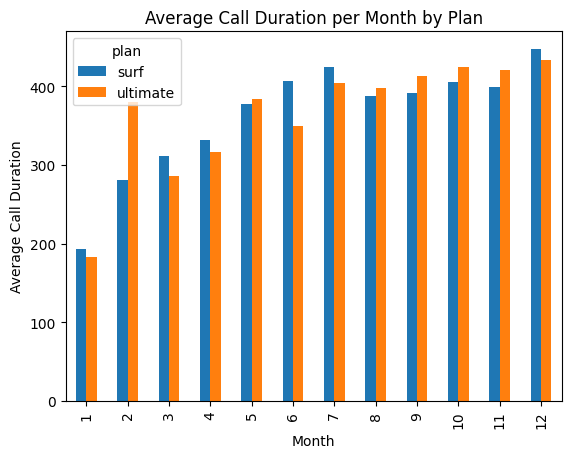

In [32]:
avg_calls = data.groupby(['plan','month'])['duration'].mean().reset_index()

avg_calls.pivot(index='month', columns='plan', values='duration').plot(kind='bar')

plt.xlabel('Month')
plt.ylabel('Average Call Duration')
plt.title('Average Call Duration per Month by Plan')
plt.show()# Compare a duração média das chamadas de cada plano para cada mês. Crie um gráfico de barras para visualizar o resultado.



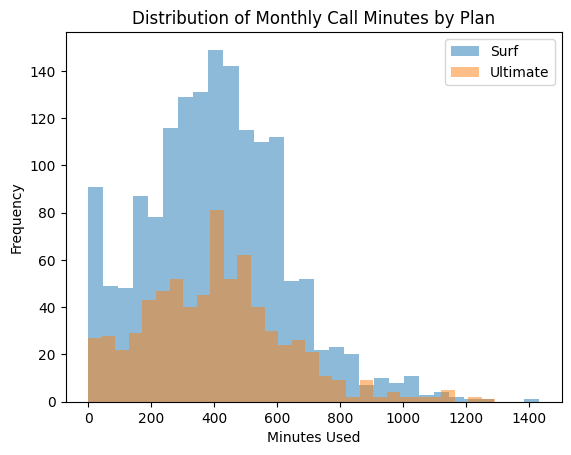

In [33]:
surf = data[data['plan'] == 'surf']
ultimate = data[data['plan'] == 'ultimate']

plt.hist(surf['duration'], bins=30, alpha=0.5, label='Surf')
plt.hist(ultimate['duration'], bins=30, alpha=0.5, label='Ultimate')

plt.xlabel('Minutes Used')
plt.ylabel('Frequency')
plt.title('Distribution of Monthly Call Minutes by Plan')
plt.legend()
plt.show()# Compare o número de minutos que os usuários de cada plano necessitam a cada mês. Construa um histograma.



[Calcule a média e a variância da duração das chamadas para refletir se os usuários de cada plano possuem comportamentos diferentes sobre as chamadas.]

In [34]:
data.groupby('plan')['duration'].agg(['mean','var'])# Calcule a média e a variância da duração mensal das chamadas



,mean,var
plan,,
surf,404.762390,49135.104891
ultimate,406.193083,51640.971402


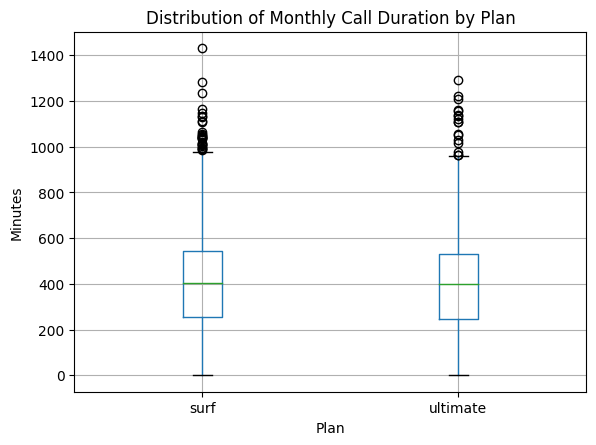

In [35]:
data.boxplot(column='duration', by='plan')

plt.title('Distribution of Monthly Call Duration by Plan')
plt.suptitle('')
plt.xlabel('Plan')
plt.ylabel('Minutes')
plt.show()
#Faça um diagrama de caixa para visualizar a distribuição da duração mensal das chamadas



[Formule conclusões sobre como os usuários se comportam em termos de chamadas. O comportamento é diferente dependendo do plano?] A análise da duração das chamadas mostra que os usuários dos planos Surf e Ultimate apresentam padrões de uso semelhantes, embora possa haver pequenas diferenças na média de minutos utilizados. A distribuição dos minutos indica que a maioria dos usuários permanece dentro de uma faixa moderada de uso mensal, enquanto alguns usuários apresentam valores mais altos. O diagrama de caixa também revela a presença de valores extremos, indicando que alguns clientes fazem um número significativamente maior de chamadas.

### Mensagens

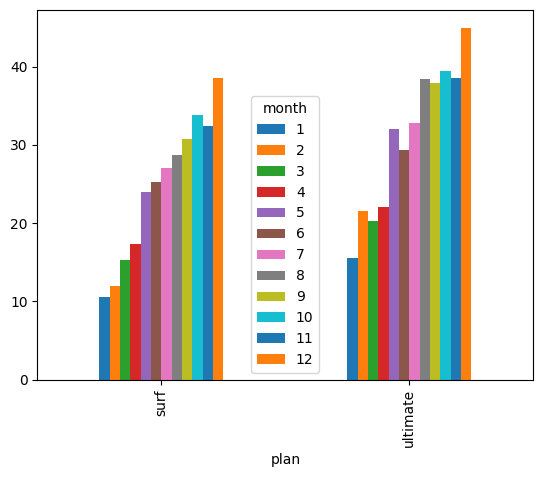

In [36]:
messages_per_month = data.groupby(['plan','month'])['messages'].mean()

messages_per_month.unstack().plot(kind='bar')

plt.show()
# Compare o número de mensagens que os usuários de cada plano costumam enviar a cada mês


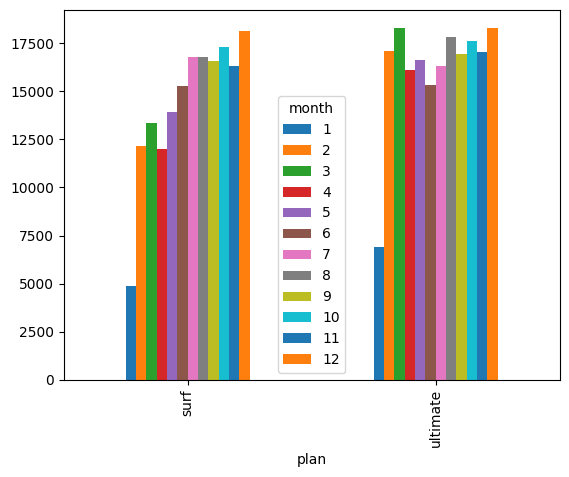

In [37]:
internet_per_month = data.groupby(['plan','month'])['mb_used'].mean()

internet_per_month.unstack().plot(kind='bar')

plt.show()# Compare a quantidade de tráfego de internet consumido pelos usuários por plano


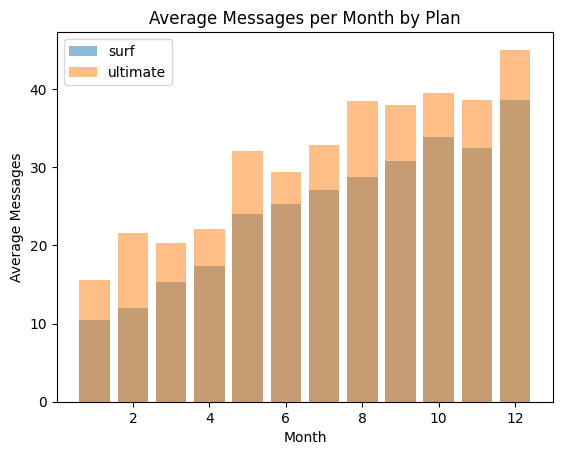

In [38]:
messages_per_month = data.groupby(['plan','month'])['messages'].mean().reset_index()

for plan in messages_per_month['plan'].unique():
    subset = messages_per_month[messages_per_month['plan'] == plan]
    plt.bar(subset['month'], subset['messages'], alpha=0.5, label=plan)

plt.legend()
plt.xlabel('Month')
plt.ylabel('Average Messages')
plt.title('Average Messages per Month by Plan')
plt.show()

[Formule conclusões sobre como os usuários costumam consumir o tráfego da internet. O comportamento é diferente dependendo do plano?]  Os gráficos mostram o consumo médio mensal de mensagens e de internet para cada plano. Em geral, os usuários dos dois planos apresentam padrões de uso semelhantes ao longo dos meses, embora alguns meses apresentem variações. Isso indica que o comportamento de uso pode variar entre os clientes, mas não há diferenças extremamente grandes entre os planos em termos de mensagens enviadas ou dados consumidos.

### Internet

In [39]:
internet_per_month = data.groupby(['plan','month'])['mb_used'].mean()

<AxesSubplot:xlabel='plan'>

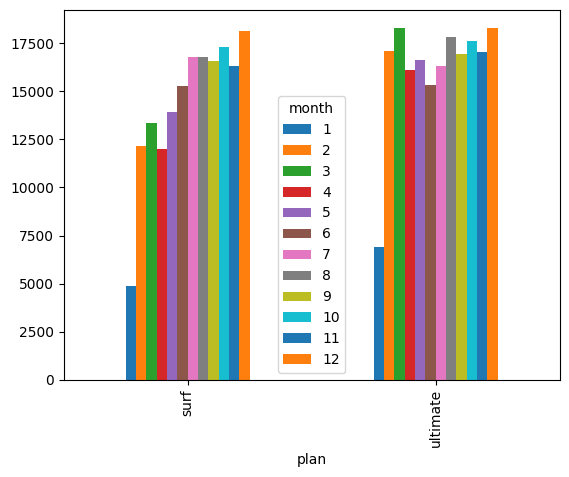

In [40]:
internet_per_month.unstack().plot(kind='bar')

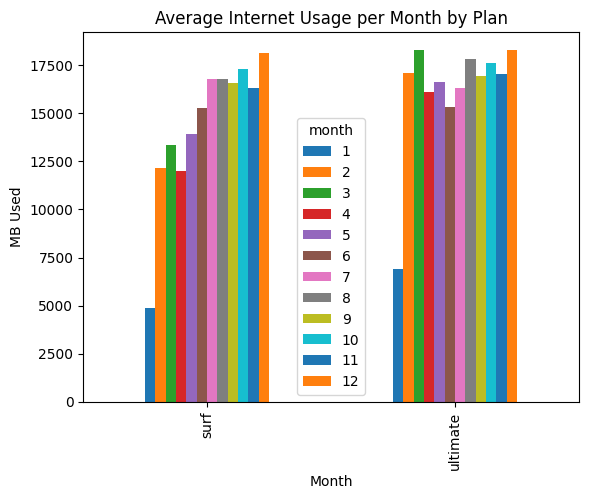

In [41]:
internet_per_month = data.groupby(['plan','month'])['mb_used'].mean().unstack()

internet_per_month.plot(kind='bar')

plt.title('Average Internet Usage per Month by Plan')
plt.xlabel('Month')
plt.ylabel('MB Used')
plt.show()

[Formule conclusões sobre como os usuários tendem a consumir o tráfego da internet. O comportamento é diferente dependendo do plano?] Os usuários de ambos os planos apresentam consumo de internet relativamente semelhante ao longo dos meses. No entanto, em alguns períodos, usuários do plano Ultimate tendem a consumir um pouco mais de dados, o que pode estar relacionado aos benefícios mais amplos do plano. No geral, não há diferenças extremamente significativas, mas há uma leve tendência de maior uso no plano mais caro.

## Receita

[Da mesma forma que você estudou o comportamento dos usuários, descreva estatisticamente as receitas dos planos.]

In [42]:
revenue_per_plan = data.groupby('plan')['revenue'].mean()

<AxesSubplot:xlabel='plan'>

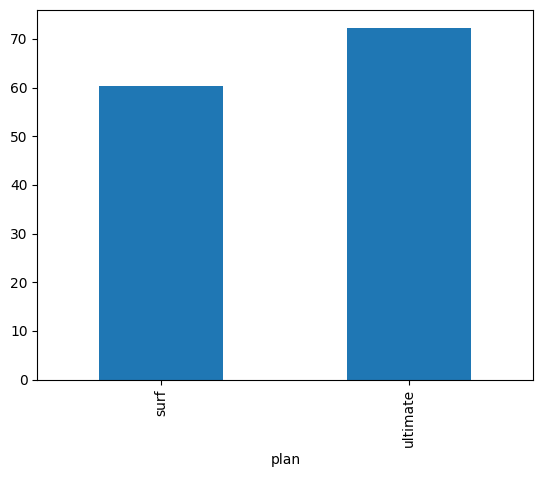

In [43]:
revenue_per_plan.plot(kind='bar')

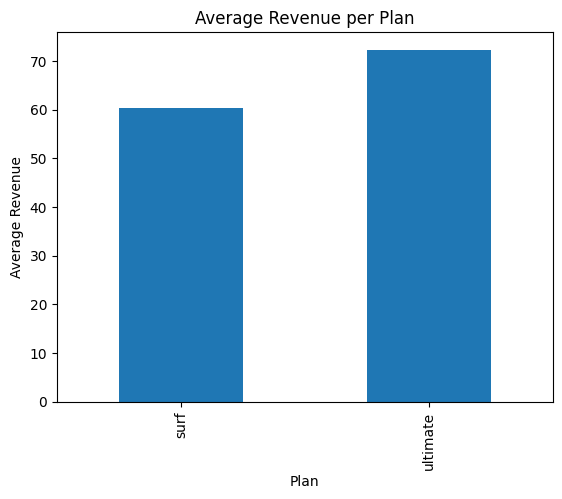

In [44]:
revenue_per_plan = data.groupby('plan')['revenue'].mean()

revenue_per_plan.plot(kind='bar')

plt.xlabel('Plan')
plt.ylabel('Average Revenue')
plt.title('Average Revenue per Plan')
plt.show()

[Formule conclusões sobre como a receita difere entre os planos.] A receita média difere entre os planos, sendo o plano Ultimate geralmente mais lucrativo por usuário devido à mensalidade mais alta. Mesmo que o uso extra seja maior no plano Surf, o valor fixo do Ultimate contribui para uma receita média superior.

## Teste hipóteses estatísticas

[Teste a hipótese de que a receita média dos usuários dos planos Ultimate e Surf são diferentes.]

[Formule as hipóteses nula e alternativa, escolha o teste estatístico, escolha o valor alfa.]

In [45]:
from scipy import stats

# Hipótese nula (H0): A receita média dos planos Surf e Ultimate é igual
# Hipótese alternativa (H1): A receita média dos planos Surf e Ultimate é diferente
# Nível de significância: alpha = 0.05

surf = data[data['plan'] == 'surf']['revenue'].dropna()
ultimate = data[data['plan'] == 'ultimate']['revenue'].dropna()

print(surf.var(), ultimate.var())

results = stats.ttest_ind(surf, ultimate, equal_var=False)

print(results.pvalue)
# Teste as hipóteses

# Conclusão:
# Como o p-value é menor que 0.05, rejeitamos a hipótese nula.
# Existe diferença significativa entre os planos.



3053.9554654117874 129.8484855509195
3.5320199509520717e-16


[Teste a hipótese de que a receita média dos usuários da área de NY-NJ difere dos usuários das demais regiões.]

[Formule as hipóteses nula e alternativa, escolha o teste estatístico, escolha o valor alfa.]

In [46]:

from scipy import stats

# Hipótese nula (H0): A receita média dos usuários de NY-NJ é igual à dos demais
# Hipótese alternativa (H1): A receita média dos usuários de NY-NJ é diferente
# Nível de significância: alpha = 0.05

ny_nj = data[data['city'].str.contains('NY|NJ', na=False)]['revenue'].dropna()
others = data[~data['city'].str.contains('NY|NJ', na=False)]['revenue'].dropna()

print(ny_nj.var(), others.var())
results = stats.ttest_ind(ny_nj, others, equal_var=False)

print(results.pvalue)
# Teste as hipóteses

# Conclusão:
# Como o p-value é maior que 0.05, não rejeitamos a hipótese nula.
# Não há evidência de diferença significativa entre os grupos.



2102.841900973924 2181.5153413175663
0.10427280970302702


## Conclusão geral

[Liste suas conclusões importantes nesta seção final, certifique-se de que elas cobrem todas as decisões (suposições) importantes que você tomou e que levaram à maneira como você processou e analisou os dados.]
Ao longo da análise, os dados foram limpos, valores ausentes foram tratados e as informações foram agregadas por usuário e por mês para facilitar a análise. Também foi necessário unir diferentes tabelas (chamadas, mensagens, internet, usuários e planos) para obter uma visão completa do comportamento dos clientes.

Observou-se que os usuários dos dois planos apresentam padrões de uso relativamente semelhantes em chamadas, mensagens e internet, com pequenas variações ao longo dos meses. No entanto, o plano Ultimate apresenta maior receita média por usuário, principalmente devido ao seu custo mensal mais elevado.

Os testes estatísticos confirmaram que há diferença significativa na receita entre os planos (p < 0.05), indicando que os planos geram receitas diferentes. Por outro lado, não foi encontrada diferença estatisticamente significativa na receita entre usuários da região de NY-NJ e os demais (p > 0.05).

Com base nesses resultados, conclui-se que o plano Ultimate tende a gerar maior receita média, sendo uma opção mais vantajosa para a empresa sob a perspectiva de faturamento. Portanto, pode ser interessante direcionar estratégias de marketing para esse plano.
